In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random


from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


from tensorflow.keras.layers import (Input,Conv2D,MaxPooling2D,GlobalAveragePooling2D,Dense,Embedding,LSTM,Add,Dropout)

SEED=42
random.seed(SEED)
np.random.seed(SEED)

In [2]:
(x_train,y_train),(x_test,y_test)=fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
x_train=x_train.astype("float32")[...,np.newaxis]/255.0
x_test=x_test.astype("float32")[...,np.newaxis]/255.0



In [10]:
class_names=["t-shirt","pullover","shirt","dress","coat","trouser","sandal","sneaker","ankle boot","bag"]

TEMPLATES=["a photo of a {}","this picture shows a {}","an image containing a {}","a small picture of a {}","here is a {}",]

In [14]:
def make_caption(label_idx):
    name=class_names[label_idx]
    article_fix="an" +name if name[0] in "aeiou" else "a" +name
    template=random.choice(TEMPLATES)
    return "startseq "+template.format(name).replace("a"+name,article_fix)+" endseq"

In [15]:
N_TRAIN,N_TEST=4000,500
train_idx=np.random.choice(len(x_train),N_TRAIN,replace=False)
test_idx=np.random.choice(len(x_test),N_TEST,replace=False)

train_images=x_train[train_idx]
train_captions=[make_caption(int(y_train[i])) for i in train_idx]

test_images=x_test[test_idx]
test_captions=[make_caption(int(y_test[i]))for i in test_idx]

In [16]:
print("Example captions:", train_captions[:3])

Example captions: ['startseq this picture shows a bag endseq', 'startseq here is a pullover endseq', 'startseq a photo of a shirt endseq']


In [17]:
tokenizer=Tokenizer(oov_token="<unk>")

tokenizer.fit_on_texts(train_captions)

vocab_size=len(tokenizer.word_index)+1

max_len=max(len(c.split()) for c in train_captions)

print(f"Vocab size: {vocab_size}, Max caption length: {max_len}")

Vocab size: 27, Max caption length: 9


In [19]:
def encode_captions(captions):
    return tokenizer.texts_to_sequences(captions)

train_seqs=encode_captions(train_captions)
test_seqs=encode_captions(test_captions)

In [20]:
def build_sequences(images,seqs):
    X_img,X_seq,y=[],[],[]
    for img,seq in zip(images,seqs):
        for t in range(1,len(seq)):
            in_seq,out_word=seq[:t],seq[t]
            in_seq=pad_sequences([in_seq],maxlen=max_len)[0]
            X_img.append(img)
            X_seq.append(in_seq)
            y.append(out_word)
    return np.array(X_img) ,np.array(X_seq),to_categorical(y,num_classes=vocab_size)

X_img_train, X_seq_train, y_train_cap = build_sequences(train_images, train_seqs)
print("Training pairs:", X_img_train.shape[0])

Training pairs: 24816


In [21]:
EMBED_DIMS=128

image_input=Input(shape=(28,28,1),name="image_input")
cnn=Conv2D(32,(3,3),activation="relu",padding="same")(image_input)
cnn=MaxPooling2D()(cnn)
cnn=Conv2D(64,(3,3),activation="relu",padding="same")(cnn)
cnn=MaxPooling2D()(cnn)
cnn = GlobalAveragePooling2D()(cnn)
image_features=Dense(EMBED_DIMS,activation="relu")(cnn)
image_features=Dropout(0.3)(image_features)

In [24]:
seq_input=Input(shape=(max_len,),name="caption_input")
seq_embed=Embedding(vocab_size,EMBED_DIMS,mask_zero=True)(seq_input)
seq_embed=Dropout(0.3)(seq_embed)
seq_features=LSTM(EMBED_DIMS)(seq_embed)

In [25]:
merged=Add()([image_features,seq_features])
merged=Dense(EMBED_DIMS,activation="relu")(merged)
output=Dense(vocab_size,activation="softmax")(merged)

caption_model=Model(inputs=[image_input,seq_input],outputs=output)
caption_model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])
caption_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)      │ (None, 28, 28, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 28, 28, 32)        │             320 │ image_input[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 14, 14, 32)        │               0 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 14, 14, 64)        │          18,496 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 7, 7, 64)          │               0 │ conv2d_1[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ caption_input (InputLayer)    │ (None, 9)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 64)                │               0 │ max_pooling2d_1[0][0]      │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding (Embedding)         │ (None, 9, 128)            │           3,456 │ caption_input[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │           8,320 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 9, 128)            │               0 │ embedding[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal (NotEqual)          │ (None, 9)                 │               0 │ caption_input[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm (LSTM)                   │ (None, 128)               │         131,584 │ dropout_1[0][0],           │
│                               │                           │                 │ not_equal[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 128)               │               0 │ dropout[0][0], lstm[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 128)               │          16,512 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 27)                │           3,48

 Total params: 182,171 (711.61 KB)

 Trainable params: 182,171 (711.61 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history = caption_model.fit(
    [X_img_train, X_seq_train], y_train_cap,
    epochs=10, batch_size=64, validation_split=0.1, verbose=1
)

Epoch 1/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 23s 43ms/step - accuracy: 0.6020 - loss: 1.3444 - val_accuracy: 0.7933 - val_loss: 0.4873
Epoch 2/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.7858 - loss: 0.4791 - val_accuracy: 0.8203 - val_loss: 0.4192
Epoch 3/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8036 - loss: 0.4346 - val_accuracy: 0.8376 - val_loss: 0.3888
Epoch 4/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8178 - loss: 0.4035 - val_accuracy: 0.8268 - val_loss: 0.4033
Epoch 5/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8227 - loss: 0.3927 - val_accuracy: 0.8187 - val_loss: 0.3807
Epoch 6/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8256 - loss: 0.3826 - val_accuracy: 0.8259 - val_loss: 0.3801
Epoch 7/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8260 - loss: 0.3765 - val_accuracy: 0.8384 - val_loss: 0.3624
Epoch 8/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.8291 - loss: 0.3703 - 

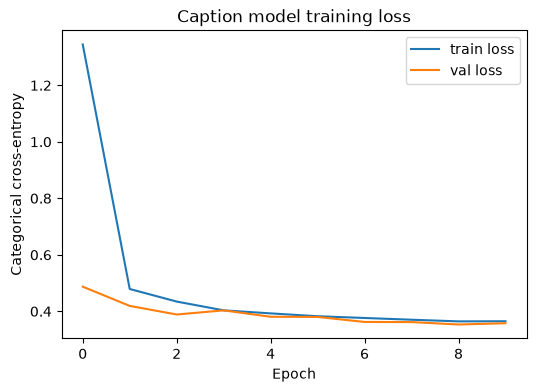

In [27]:
plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.title("Caption model training loss")
plt.xlabel("Epoch")
plt.ylabel("Categorical cross-entropy")
plt.legend()

In [28]:
index_to_word={idx:word for word,idx in tokenizer.word_index.items()}

In [31]:
def generate_caption(image,max_length=max_len):
    in_text="startseq"
    for _ in range(max_length):
        seq=tokenizer.texts_to_sequences([in_text])[0]
        seq=pad_sequences([seq],maxlen=max_length)
        pred=caption_model.predict([np.expand_dims(image,0),seq],verbose=0)
        next_idx=int(np.argmax(pred))
        next_word=index_to_word.get(next_idx,"")
        if next_word=="" or next_word=="endseq":
            break
        in_text+=" "+next_word

    return in_text.replace("startseq","").strip()
        

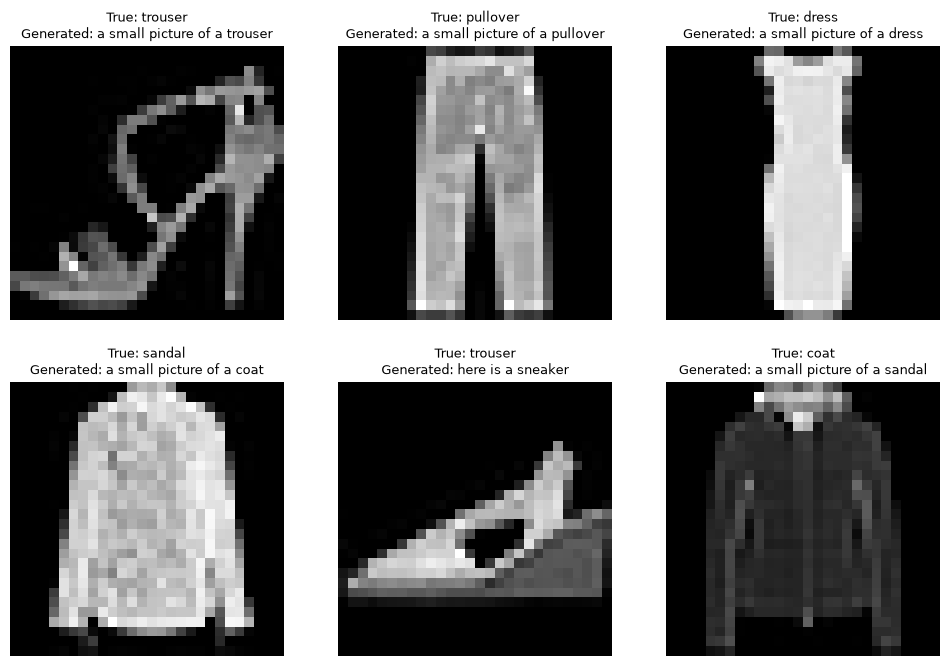

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
sample_indices = np.random.choice(len(test_images), 6, replace=False)
for ax, idx in zip(axes.ravel(), sample_indices):
    img = test_images[idx]
    true_label = class_names[int(y_test[test_idx[idx]])]
    pred_caption = generate_caption(img)
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"True: {true_label}\nGenerated: {pred_caption}", fontsize=9)
    ax.axis("off")